#  Učitavanje i pregled podataka




In [1]:
import pandas as pd
import numpy as np
import warnings

# --- Vizualizacija ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Sklearn preprocessing & model selection ---
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, cohen_kappa_score, confusion_matrix, classification_report
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

# --- Imbalanced learning ---
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek

# --- Google Colab (ako je potrebno) ---
from google.colab import drive

# ============================
# POSTAVLJANJE OPCIJA I STILA
# ============================

# Upozorenja isključena za čist izlaz
warnings.filterwarnings('ignore')

# Stil i paleta za vizualizaciju
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")


In [2]:
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df = pd.read_csv('/content/drive/MyDrive/clean_dataset.csv')

In [4]:
df.head()

,Attrition_Flag_clean,Customer_Age_clean,Gender_clean,Dependent_count_clean,Education_Level_clean,Marital_Status_clean,Income_Category_clean,Card_Category_clean,Months_on_book_clean,Total_Relationship_Count_clean,Months_Inactive_clean,Contacts_Count_clean,Credit_Limit_clean,Total_Revolving_Bal_clean,Avg_Open_To_Buy_clean,Total_Amt_Chng_clean,Total_Trans_Amt_clean,Total_Trans_Ct_clean,Total_Ct_Chng_clean,Avg_Utilization_Ratio_clean
0,Existing Customer,45.0,M,3.0,High School,Married,$60K - $80K,Blue,39.0,4.0,1.0,3.0,4537.0,777.0,3473.0,0.737,1144.0,42.0,1.625,0.061
1,Existing Customer,49.0,F,5.0,Graduate,Single,Less than $40K,Blue,44.0,6.0,1.0,2.0,8256.0,1249.0,3473.0,0.737,1291.0,67.0,3.714,0.105
2,Existing Customer,46.0,M,3.0,Graduate,Married,$80K - $120K,Blue,36.0,4.0,1.0,2.0,3418.0,0.0,3418.0,2.594,1887.0,20.0,2.333,0.000
3,Existing Customer,46.0,F,4.0,High School,Unknown,Less than $40K,Blue,34.0,3.0,4.0,2.0,3313.0,1249.0,796.0,1.405,1171.0,20.0,2.333,0.760
4,Existing Customer,46.0,M,3.0,Uneducated,Married,$60K - $80K,Blue,36.0,5.0,2.0,2.0,4716.0,0.0,4716.0,2.175,3899.0,28.0,2.500,0.000


# Eksplorativna analiza podataka

In [5]:
print("=" * 60)
print("OSNOVNE INFORMACIJE O PODACIMA")
print("=" * 60)
print(df.info())
print("\n" + "=" * 60)
print("STATISTIČKI PREGLED")
print("=" * 60)
print(df.describe())
print("\n" + "=" * 60)
print("NEDOSTAJUĆE VRIJEDNOSTI")
print("=" * 60)
print(df.isnull().sum())

OSNOVNE INFORMACIJE O PODACIMA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Attrition_Flag_clean            10127 non-null  object 
 1   Customer_Age_clean              10127 non-null  float64
 2   Gender_clean                    10127 non-null  object 
 3   Dependent_count_clean           10127 non-null  float64
 4   Education_Level_clean           10127 non-null  object 
 5   Marital_Status_clean            10127 non-null  object 
 6   Income_Category_clean           10127 non-null  object 
 7   Card_Category_clean             10127 non-null  object 
 8   Months_on_book_clean            10127 non-null  float64
 9   Total_Relationship_Count_clean  10127 non-null  float64
 10  Months_Inactive_clean           10127 non-null  float64
 11  Contacts_Count_clean            10127 non-null  float64
 12  C

# Analiza ciljne varijable (class distribution)


DISTRIBUCIJA KLASA
Attrition_Flag_clean
Existing Customer    8483
Attrited Customer    1644
Name: count, dtype: int64

Procenat po klasama:
Attrition_Flag_clean
Existing Customer    83.76617
Attrited Customer    16.23383
Name: proportion, dtype: float64


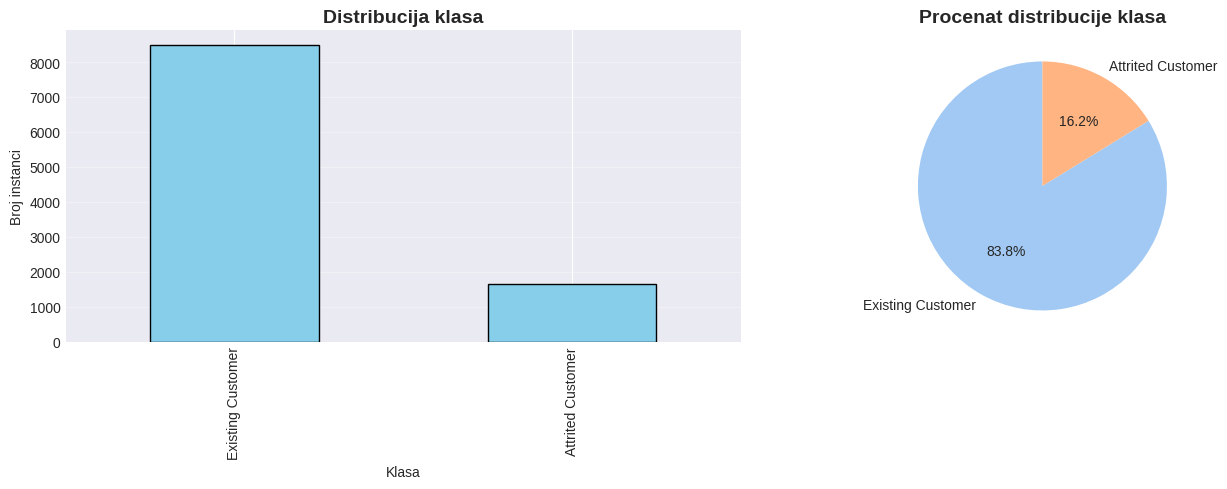


⚠ Omjer nebalansiranosti: 5.16
⚠ Dataset je NEBALANSIRAN


In [6]:
# Identifikuj ciljnu varijablu - prilagodi naziv kolone
target_column = 'Attrition_Flag_clean'

# Analiza distribucije klasa
print("\n" + "=" * 60)
print("DISTRIBUCIJA KLASA")
print("=" * 60)
class_dist = df[target_column].value_counts()
print(class_dist)
print(f"\nProcenat po klasama:")
print(df[target_column].value_counts(normalize=True) * 100)

# Vizualizacija distribucije
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot
class_dist.plot(kind='bar', ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title('Distribucija klasa', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Klasa')
axes[0].set_ylabel('Broj instanci')
axes[0].grid(axis='y', alpha=0.3)

# Pie chart
axes[1].pie(class_dist.values, labels=class_dist.index, autopct='%1.1f%%',
            startangle=90, colors=sns.color_palette("pastel"))
axes[1].set_title('Procenat distribucije klasa', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Provjera balansiranosti
imbalance_ratio = class_dist.max() / class_dist.min()
print(f"\n⚠ Omjer nebalansiranosti: {imbalance_ratio:.2f}")
if imbalance_ratio > 1.5:
    print("⚠ Dataset je NEBALANSIRAN")
else:
    print("✓ Dataset je relativno BALANSIRAN")

Zbog izražene nebalansiranosti klasa (≈84% naspram 16%), standardne metrike poput tačnosti mogu biti varljive, te će se u nastavku koristiti metode resamplinga (SMOTE) kako bi se poboljšala osjetljivost modela na manjinsku klasu.

# Priprema podataka - Provjera i obrada

In [7]:

print("=" * 60)
print("PRIPREMA PODATAKA ZA k-NN")
print("=" * 60)

# 1) Separacija features i target varijable
X = df.drop(columns=[target_column]).copy()
y = df[target_column].copy()

print(f"\nDimenzije:\nX (features): {X.shape}\ny (target): {y.shape}")

# 2) Tipovi podataka
print("\n" + "=" * 60)
print("TIPOVI PODATAKA")
print("=" * 60)
print(X.dtypes.value_counts())

# 3) Identifikacija kolona
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"\nKategoričke kolone ({len(categorical_cols)}): {categorical_cols}")
print(f"Numeričke kolone ({len(numerical_cols)}): {numerical_cols}")

# 4) Nedostajuće vrijednosti – samo izvještaj (imputacija će u pipeline)
missing_total = X.isnull().sum().sum()
if missing_total > 0:
    print("\n⚠ Upozorenje: postoje nedostajuće vrijednosti u feature-ima.")
    print(X.isnull().sum()[X.isnull().sum() > 0])
else:
    print("\n✓ Nema nedostajućih vrijednosti u feature-ima.")

# 5) Enkodiranje target varijable (ovo je u redu)
if y.dtype == 'object' or str(y.dtype).startswith('category'):
    print("\n⚙ Enkodiram target varijablu...")
    le_target = LabelEncoder()
    y = le_target.fit_transform(y)
    print(f"✓ Klase (mapping): {dict(zip(le_target.classes_, le_target.transform(le_target.classes_)))}")
else:
    le_target = None
    print("\n✓ Target je već numerički.")

print("\n✓ Priprema podataka završena!")

PRIPREMA PODATAKA ZA k-NN

Dimenzije:
X (features): (10127, 19)
y (target): (10127,)

TIPOVI PODATAKA
float64    14
object      5
Name: count, dtype: int64

Kategoričke kolone (5): ['Gender_clean', 'Education_Level_clean', 'Marital_Status_clean', 'Income_Category_clean', 'Card_Category_clean']
Numeričke kolone (14): ['Customer_Age_clean', 'Dependent_count_clean', 'Months_on_book_clean', 'Total_Relationship_Count_clean', 'Months_Inactive_clean', 'Contacts_Count_clean', 'Credit_Limit_clean', 'Total_Revolving_Bal_clean', 'Avg_Open_To_Buy_clean', 'Total_Amt_Chng_clean', 'Total_Trans_Amt_clean', 'Total_Trans_Ct_clean', 'Total_Ct_Chng_clean', 'Avg_Utilization_Ratio_clean']

✓ Nema nedostajućih vrijednosti u feature-ima.

⚙ Enkodiram target varijablu...
✓ Klase (mapping): {'Attrited Customer': np.int64(0), 'Existing Customer': np.int64(1)}

✓ Priprema podataka završena!


S obzirom da k-NN algoritam zasniva odluku na udaljenosti između instanci, enkodiranje kategorijskih varijabli i normalizacija numeričkih obilježja biće izvršeni nakon podjele podataka kako bi se spriječio data leakage i osigurala korektna evaluacija modela.

# Podjela podataka (Train/Validation/Test)

PODJELA PODATAKA
Trening set: 7092 uzoraka (70.0%)
Validacioni set: 1515 uzoraka (15.0%)
Test set: 1520 uzoraka (15.0%)


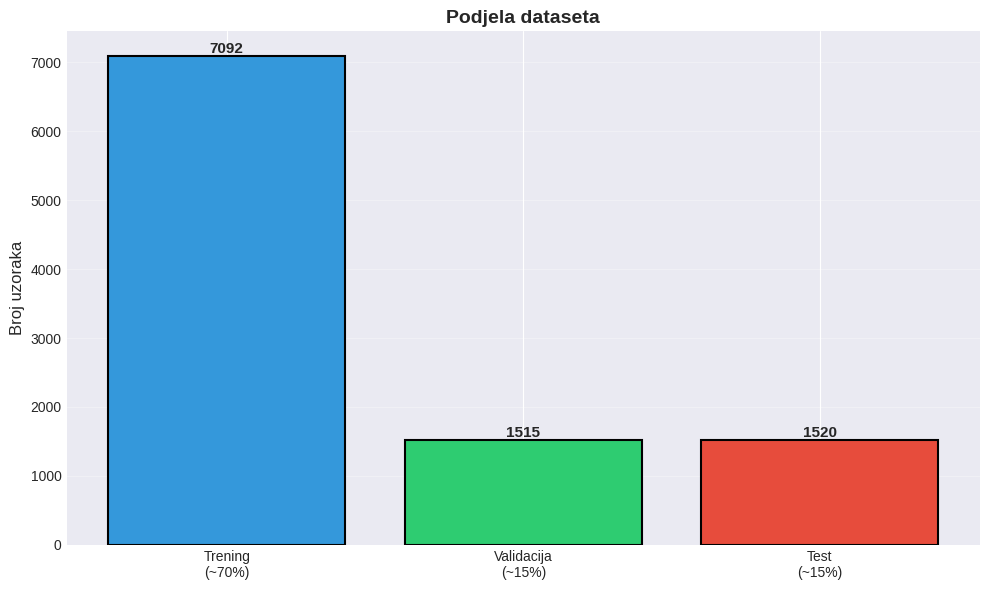


✓ Podjela podataka završena!


In [9]:
print("=" * 60)
print("PODJELA PODATAKA")
print("=" * 60)

# Strategija: 70% train, 15% validation, 15% test
# Prvo odvoji test set (15%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

# Zatim podijeli preostale podatke na train (70%) i validation (15%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.176, random_state=42, stratify=y_temp
)  # 0.176 * 0.85 ≈ 0.15 od ukupnog

print(f"Trening set: {X_train.shape[0]} uzoraka ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Validacioni set: {X_val.shape[0]} uzoraka ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"Test set: {X_test.shape[0]} uzoraka ({X_test.shape[0]/len(X)*100:.1f}%)")

# Vizualizacija podjele
fig, ax = plt.subplots(figsize=(10, 6))
split_sizes = [len(X_train), len(X_val), len(X_test)]
split_labels = ['Trening\n(~70%)', 'Validacija\n(~15%)', 'Test\n(~15%)']
colors = ['#3498db', '#2ecc71', '#e74c3c']

bars = ax.bar(split_labels, split_sizes, color=colors, edgecolor='black', linewidth=1.5)
ax.set_ylabel('Broj uzoraka', fontsize=12)
ax.set_title('Podjela dataseta', fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# Dodaj brojeve na stubove
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{int(height)}',
            ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

print("\n✓ Podjela podataka završena!")

In [10]:

from collections import Counter
import numpy as np

def dist(y, name):
    c = Counter(y)
    total = len(y)
    print(f"{name}: total={total} | " +
          " | ".join([f"{cls}={c[cls]} ({c[cls]/total*100:.2f}%)" for cls in sorted(c.keys())]))

print("\nDistribucija klasa po skupovima:")
dist(y_train, "Train")
dist(y_val, "Validation")
dist(y_test, "Test")


Distribucija klasa po skupovima:
Train: total=7092 | 0=1151 (16.23%) | 1=5941 (83.77%)
Validation: total=1515 | 0=246 (16.24%) | 1=1269 (83.76%)
Test: total=1520 | 0=247 (16.25%) | 1=1273 (83.75%)


# Normalizacija podataka

NORMALIZACIJA PODATAKA

⚠ k-NN algoritam je OSJETLJIV na skalu podataka!
Primjenjujem StandardScaler (z-score normalizaciju) nad NUMERIČKIM kolonama...

✓ Normalizacija završena!

Primjer - prije i poslije normalizacije (prvi uzorak, numeričke kolone):
Prije:  [46.  2. 36.  6.  2.]...
Poslije: [-0.03591396 -0.2165143   0.01215887  1.56721957 -0.30802736]...


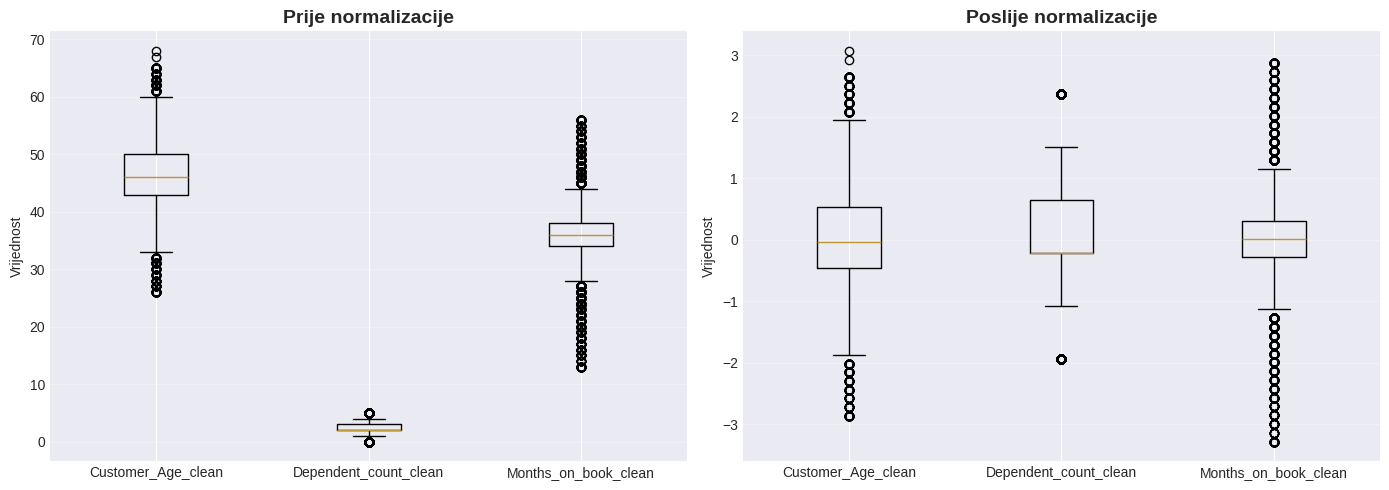

In [11]:
print("=" * 60)
print("NORMALIZACIJA PODATAKA")
print("=" * 60)
print("\n⚠ k-NN algoritam je OSJETLJIV na skalu podataka!")
print("Primjenjujem StandardScaler (z-score normalizaciju) nad NUMERIČKIM kolonama...\n")

# Kopije dataset-a
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

# Inicijalizuj scaler
scaler = StandardScaler()

# Fit samo na TRAIN i transformacija svih setova (bez data leakage-a)
X_train_scaled[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_val_scaled[numerical_cols] = scaler.transform(X_val[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test[numerical_cols])

print("✓ Normalizacija završena!")

print("\nPrimjer - prije i poslije normalizacije (prvi uzorak, numeričke kolone):")
print(f"Prije:  {X_train[numerical_cols].iloc[0].values[:5]}...")
print(f"Poslije: {X_train_scaled[numerical_cols].iloc[0].values[:5]}...")

# Vizualizacija efekta normalizacije (prvih 5 numeričkih feature-a)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

num_plot_cols = numerical_cols[:3]

# Prije normalizacije
axes[0].boxplot([X_train[col] for col in num_plot_cols],
                labels=[col for col in num_plot_cols])
axes[0].set_title('Prije normalizacije', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Vrijednost')
axes[0].grid(axis='y', alpha=0.3)

# Poslije normalizacije
axes[1].boxplot([X_train_scaled[col] for col in num_plot_cols],
                labels=[col for col in num_plot_cols])
axes[1].set_title('Poslije normalizacije', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Vrijednost')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

S obzirom da k-NN algoritam koristi udaljenosti između instanci, normalizacija numeričkih obilježja je ključna kako bi se spriječilo da varijable sa većim rasponom vrijednosti dominiraju procesom odlučivanja.

# Odabir optimalnog k

ODABIR OPTIMALNE VRIJEDNOSTI k (CROSS-VALIDATION)

⚙ Testiram k vrijednosti od 1 do 30 koristeći 5-fold CV...

k= 5: CV Accuracy = 0.8880
k=10: CV Accuracy = 0.8879
k=15: CV Accuracy = 0.8841
k=20: CV Accuracy = 0.8844
k=25: CV Accuracy = 0.8837
k=30: CV Accuracy = 0.8806

🎯 OPTIMALNO k = 8
   Prosječna CV tačnost = 0.8902


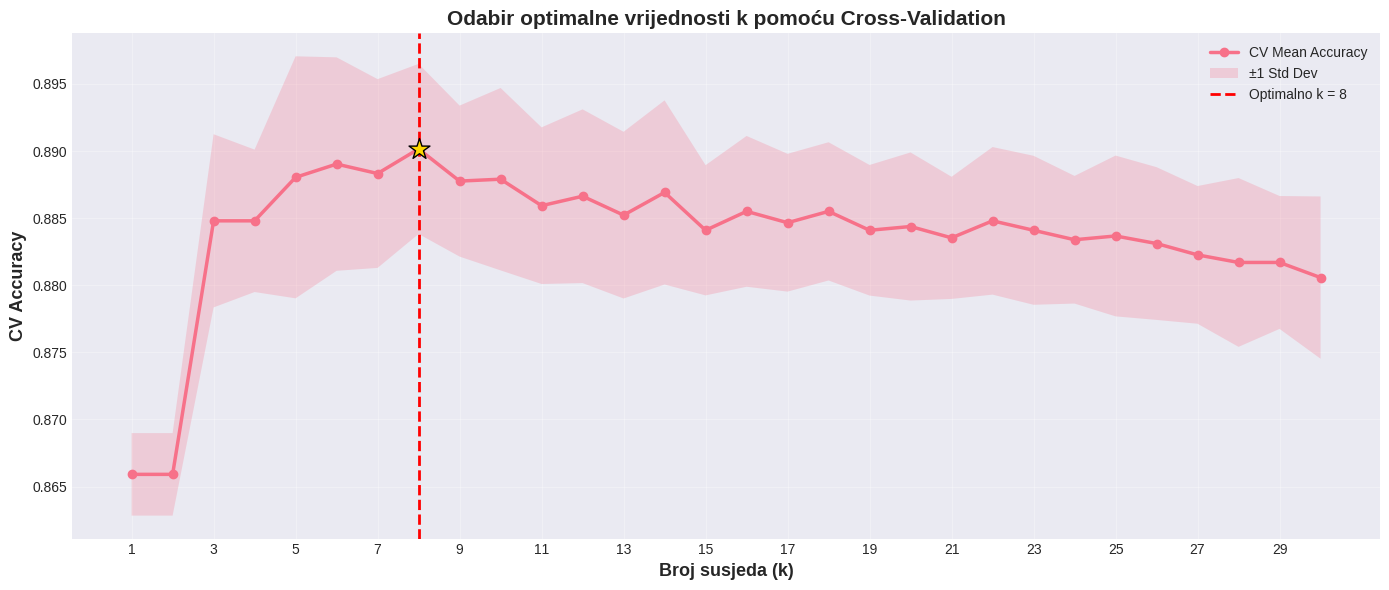

In [12]:
print("=" * 60)
print("ODABIR OPTIMALNE VRIJEDNOSTI k (CROSS-VALIDATION)")
print("=" * 60)

# Raspon k vrijednosti
k_range = range(1, 31)

cv_mean_scores = []
cv_std_scores = []

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("\n⚙ Testiram k vrijednosti od 1 do 30 koristeći 5-fold CV...\n")

for k in k_range:
    knn = KNeighborsClassifier(
        n_neighbors=k,
        weights='distance',   # razumna default postavka
        metric='minkowski',
        p=2                   # Euklidska udaljenost
    )

    cv_scores = cross_val_score(
        knn,
        X_train_scaled[numerical_cols],
        y_train,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    cv_mean_scores.append(cv_scores.mean())
    cv_std_scores.append(cv_scores.std())

    if k % 5 == 0:
        print(f"k={k:2d}: CV Accuracy = {cv_scores.mean():.4f}")

# Optimalno k
optimal_k = k_range[int(np.argmax(cv_mean_scores))]
optimal_acc = max(cv_mean_scores)

print("\n" + "=" * 60)
print(f"🎯 OPTIMALNO k = {optimal_k}")
print(f"   Prosječna CV tačnost = {optimal_acc:.4f}")
print("=" * 60)

# Vizualizacija
plt.figure(figsize=(14, 6))

plt.plot(k_range, cv_mean_scores, 'o-', linewidth=2.5, label='CV Mean Accuracy')
plt.fill_between(
    k_range,
    np.array(cv_mean_scores) - np.array(cv_std_scores),
    np.array(cv_mean_scores) + np.array(cv_std_scores),
    alpha=0.25,
    label='±1 Std Dev'
)

plt.axvline(
    x=optimal_k,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Optimalno k = {optimal_k}'
)

plt.scatter(
    optimal_k,
    optimal_acc,
    s=250,
    color='gold',
    edgecolors='black',
    zorder=5,
    marker='*'
)

plt.xlabel('Broj susjeda (k)', fontsize=13, fontweight='bold')
plt.ylabel('CV Accuracy', fontsize=13, fontweight='bold')
plt.title('Odabir optimalne vrijednosti k pomoću Cross-Validation', fontsize=15, fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(range(1, 31, 2))
plt.tight_layout()
plt.show()

Optimalna vrijednost parametra k=8 određena je korištenjem 5-struke unakrsne validacije nad trening skupom, čime je izbjegnuta pristrasnost i osigurana procjena performansi modela.

# Izgradnja k-NN modela sa optimalnim parametrima

In [13]:
print("\n" + "=" * 60)
print("TUNING PRAGA – VALIDACIJA I TEST (klasa 0 = Attrited)")
print("=" * 60)

# 1) Kreiraj i istreniraj k-NN model sa optimalnim k
knn_optimal = KNeighborsClassifier(
    n_neighbors=8,
    weights='distance',   # optimalno
    metric='minkowski',
    p=2
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# Fit modela na preprocesirane podatke (numeričke + kategorijske)
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed   = preprocessor.transform(X_val)
X_test_processed  = preprocessor.transform(X_test)

knn_optimal.fit(X_train_processed, y_train)

# 2) Izračunaj vjerovatnoće za klasu 0 (Attrited) na VAL i TEST setovima
idx0 = list(knn_optimal.classes_).index(0)
p0_val  = knn_optimal.predict_proba(X_val_processed)[:, idx0]
p0_test = knn_optimal.predict_proba(X_test_processed)[:, idx0]

# 3) Pragovi koje testiramo
thresholds = [0.15, 0.20, 0.25]

# Funkcija za evaluaciju s pragom
def eval_with_threshold(y_true, p_pos, thr, pos_label=0):
    y_pred = np.where(p_pos >= thr, pos_label, 1 - pos_label)
    return {
        "Precision_0": precision_score(y_true, y_pred, pos_label=pos_label, zero_division=0),
        "Recall_0":    recall_score(y_true, y_pred,    pos_label=pos_label, zero_division=0),
        "F1_0":        f1_score(y_true,  y_pred,       pos_label=pos_label, zero_division=0),
        "F1_macro":    f1_score(y_true,  y_pred, average='macro'),
        "BalAcc":      balanced_accuracy_score(y_true, y_pred),
        "Accuracy":    accuracy_score(y_true, y_pred),
    }

# 4) Evaluacija po pragovima
for thr in thresholds:
    met_v = eval_with_threshold(y_val, p0_val, thr, pos_label=0)
    met_t = eval_with_threshold(y_test, p0_test, thr, pos_label=0)

    print(f"\nPrag = {thr:.2f}")
    print("  VALIDACIJA:")
    print(f"    • Precision_0: {met_v['Precision_0']:.4f} | Recall_0: {met_v['Recall_0']:.4f} | F1_0: {met_v['F1_0']:.4f}")
    print(f"    • F1-Macro:    {met_v['F1_macro']:.4f} | Balanced Acc: {met_v['BalAcc']:.4f} | Accuracy: {met_v['Accuracy']:.4f}")
    print("  TEST:")
    print(f"    • Precision_0: {met_t['Precision_0']:.4f} | Recall_0: {met_t['Recall_0']:.4f} | F1_0: {met_t['F1_0']:.4f}")
    print(f"    • F1-Macro:    {met_t['F1_macro']:.4f} | Balanced Acc: {met_t['BalAcc']:.4f} | Accuracy: {met_t['Accuracy']:.4f}")


TUNING PRAGA – VALIDACIJA I TEST (klasa 0 = Attrited)

Prag = 0.15
  VALIDACIJA:
    • Precision_0: 0.4970 | Recall_0: 0.6748 | F1_0: 0.5724
    • F1-Macro:    0.7356 | Balanced Acc: 0.7712 | Accuracy: 0.8363
  TEST:
    • Precision_0: 0.5029 | Recall_0: 0.6923 | F1_0: 0.5826
    • F1-Macro:    0.7414 | Balanced Acc: 0.7798 | Accuracy: 0.8388

Prag = 0.20
  VALIDACIJA:
    • Precision_0: 0.5015 | Recall_0: 0.6707 | F1_0: 0.5739
    • F1-Macro:    0.7371 | Balanced Acc: 0.7707 | Accuracy: 0.8383
  TEST:
    • Precision_0: 0.5060 | Recall_0: 0.6883 | F1_0: 0.5832
    • F1-Macro:    0.7421 | Balanced Acc: 0.7789 | Accuracy: 0.8401

Prag = 0.25
  VALIDACIJA:
    • Precision_0: 0.5847 | Recall_0: 0.5894 | F1_0: 0.5870
    • F1-Macro:    0.7533 | Balanced Acc: 0.7541 | Accuracy: 0.8653
  TEST:
    • Precision_0: 0.6096 | Recall_0: 0.6194 | F1_0: 0.6145
    • F1-Macro:    0.7695 | Balanced Acc: 0.7712 | Accuracy: 0.8737


# Evaluacija modela (konfuzijska matrica + metrike)

FINALNA EVALUACIJA NAJBOLJEG MODELA (k=8, threshold=0.25)

TAČNOST PO SETOVIMA:
  Trening set:     1.0000 (100.00%)
  Validacioni set: 0.8653 (86.53%)
  Test set:        0.8737 (87.37%)

DETALJNE METRIKE (TEST SET)
✓ Accuracy:  0.8737
✓ Precision: 0.8745
✓ Recall:    0.8737
✓ F1-Score:  0.8741
✓ Kappa:     0.5389

KONFUZIJSKA MATRICA:
[[ 153   94]
 [  98 1175]]


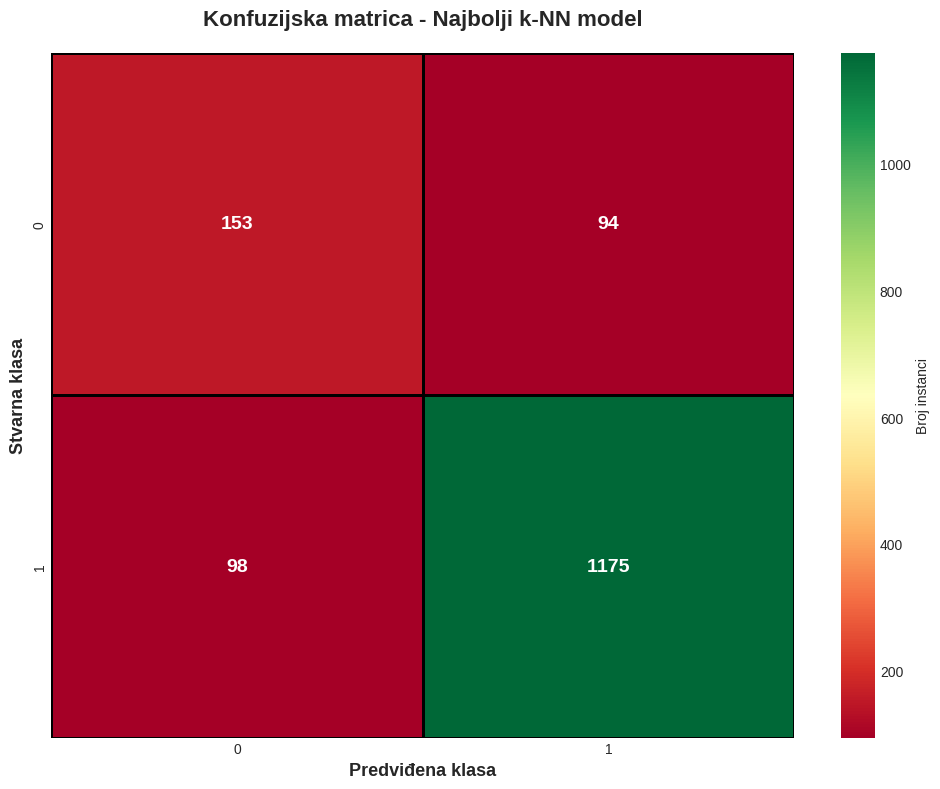


CLASSIFICATION REPORT (TEST SET)
              precision    recall  f1-score   support

           0       0.61      0.62      0.61       247
           1       0.93      0.92      0.92      1273

    accuracy                           0.87      1520
   macro avg       0.77      0.77      0.77      1520
weighted avg       0.87      0.87      0.87      1520


DODATNE METRIKE (BINARNA KLASIFIKACIJA)
✓ Sensitivity (Recall, TPR):  0.9230
✓ Specificity (TNR):          0.6194
✓ PPV (Precision):            0.9259
✓ NPV:                        0.6096
✓ False Positive Rate (FPR):  0.3806
✓ False Negative Rate (FNR):  0.0770


In [14]:
print("=" * 60)
print("FINALNA EVALUACIJA NAJBOLJEG MODELA (k=8, threshold=0.25)")
print("=" * 60)

# ---- Predikcije sa pragom 0.25 za klasu 0 (Attrited) ----
threshold = 0.25
idx0 = list(knn_optimal.classes_).index(0)

# Validacija
y_val_pred_best = np.where(knn_optimal.predict_proba(X_val_processed)[:, idx0] >= threshold, 0, 1)
# Test
y_test_pred_best = np.where(knn_optimal.predict_proba(X_test_processed)[:, idx0] >= threshold, 0, 1)

# Accuracy po setovima
train_acc_best = knn_optimal.score(X_train_processed, y_train)
val_acc_best = accuracy_score(y_val, y_val_pred_best)
test_acc_best = accuracy_score(y_test, y_test_pred_best)

print("\nTAČNOST PO SETOVIMA:")
print(f"  Trening set:     {train_acc_best:.4f} ({train_acc_best*100:.2f}%)")
print(f"  Validacioni set: {val_acc_best:.4f} ({val_acc_best*100:.2f}%)")
print(f"  Test set:        {test_acc_best:.4f} ({test_acc_best*100:.2f}%)")

# ---- Detaljne metrike za test set ----
accuracy_best = accuracy_score(y_test, y_test_pred_best)
precision_best = precision_score(y_test, y_test_pred_best, average='weighted', zero_division=0)
recall_best = recall_score(y_test, y_test_pred_best, average='weighted', zero_division=0)
f1_best = f1_score(y_test, y_test_pred_best, average='weighted', zero_division=0)
kappa_best = cohen_kappa_score(y_test, y_test_pred_best)

print("\n" + "=" * 60)
print("DETALJNE METRIKE (TEST SET)")
print("=" * 60)
print(f"✓ Accuracy:  {accuracy_best:.4f}")
print(f"✓ Precision: {precision_best:.4f}")
print(f"✓ Recall:    {recall_best:.4f}")
print(f"✓ F1-Score:  {f1_best:.4f}")
print(f"✓ Kappa:     {kappa_best:.4f}")

# ---- Konfuzijska matrica ----
cm_best = confusion_matrix(y_test, y_test_pred_best)
print("\nKONFUZIJSKA MATRICA:")
print(cm_best)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='RdYlGn',
            cbar_kws={'label': 'Broj instanci'},
            linewidths=2, linecolor='black', annot_kws={'size': 14, 'weight': 'bold'})
plt.title('Konfuzijska matrica - Najbolji k-NN model', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Stvarna klasa', fontsize=13, fontweight='bold')
plt.xlabel('Predviđena klasa', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ---- Classification report ----
print("\n" + "=" * 60)
print("CLASSIFICATION REPORT (TEST SET)")
print("=" * 60)
print(classification_report(y_test, y_test_pred_best))

# ---- Dodatne metrike za binarnu klasifikaciju ----
if len(np.unique(y)) == 2:
    tn, fp, fn, tp = cm_best.ravel()

    specificity_best = tn / (tn + fp)
    sensitivity_best = tp / (tp + fn)
    npv = tn / (tn + fn)  # Negative Predictive Value
    ppv = tp / (tp + fp)  # Positive Predictive Value (Precision)

    print("\n" + "=" * 60)
    print("DODATNE METRIKE (BINARNA KLASIFIKACIJA)")
    print("=" * 60)
    print(f"✓ Sensitivity (Recall, TPR):  {sensitivity_best:.4f}")
    print(f"✓ Specificity (TNR):          {specificity_best:.4f}")
    print(f"✓ PPV (Precision):            {ppv:.4f}")
    print(f"✓ NPV:                        {npv:.4f}")
    print(f"✓ False Positive Rate (FPR):  {fp/(fp+tn):.4f}")
    print(f"✓ False Negative Rate (FNR):  {fn/(fn+tp):.4f}")

Ovaj blok pokazuje konačne performanse najboljeg k-NN modela sa optimalnim parametrima (k=8) i pragom 0.25 za klasu 0 (Attrited).

Tačnost po setovima: model gotovo savršeno predviđa trening set (100%), dok na validacionom i test setu pokazuje visoku tačnost (~87%), što sugerira da model dobro generalizira, bez značajnog overfittinga.

Detaljne metrike: visoke vrijednosti precision, recall i F1-Score (~0.87) potvrđuju da model balansirano detektuje obje klase, a Kappa od 0.5389 pokazuje dobar nivo slaganja s nasumičnim predviđanjem.

Konfuzijska matrica i classification report pokazuju da je model posebno jak u predviđanju većinske klase 1, dok za manju klasu 0 (Attrited) ima nešto nižu preciznost i recall, što je tipično kod neuravnoteženih datasetova.

Dodatne metrike za binarnu klasifikaciju: visoka senzitivnost (0.923) i PPV (0.926) pokazuju da model dobro prepoznaje stvarne pozitivne slučajeve klase 0, dok niža specifičnost (0.619) i NPV (0.610) ukazuju na relativno veći broj lažno pozitivnih predikcija za klasu 0.

Sve u svemu, model je pouzdan i efikasan, sa blagom sklonosti ka predviđanju većinske klase, što je očekivano kod neuravnoteženih podataka.

# Unakrsna validacija modela

CROSS-VALIDATION NAJBOLJEG MODELA

⚙ Izvršavam 10-fold cross-validation na najboljem modelu...
✓ Cross-validation završena!

REZULTATI 10-FOLD CROSS-VALIDATION:
  Metrika     Mean      Std      Min      Max    Range
 Accuracy 0.884279 0.007900 0.869767 0.898837 0.029070
Precision 0.875437 0.010714 0.855275 0.892507 0.037232
   Recall 0.884279 0.007900 0.869767 0.898837 0.029070
 F1-Score 0.867789 0.010419 0.847714 0.888220 0.040507


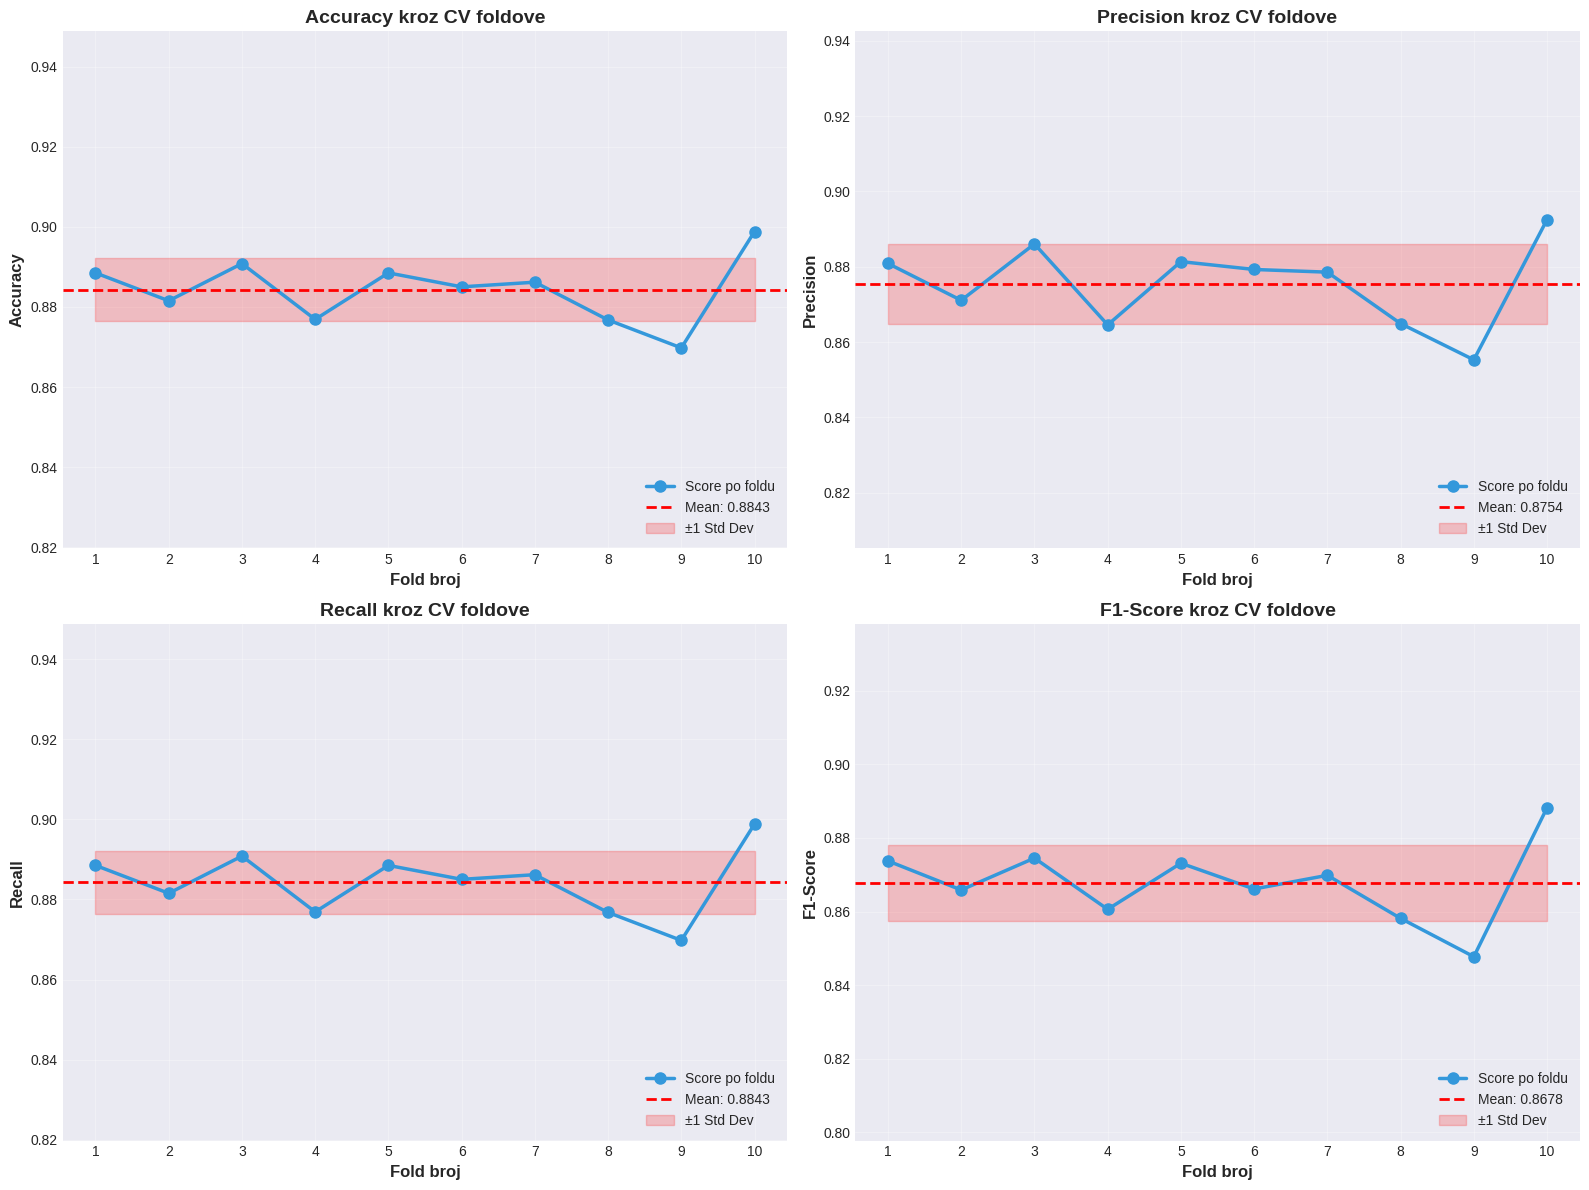


ANALIZA STABILNOSTI MODELA

Accuracy:
  Koeficijent varijacije: 0.89%
  → Model je VEOMA STABILAN

Precision:
  Koeficijent varijacije: 1.22%
  → Model je VEOMA STABILAN

Recall:
  Koeficijent varijacije: 0.89%
  → Model je VEOMA STABILAN

F1-Score:
  Koeficijent varijacije: 1.20%
  → Model je VEOMA STABILAN


In [15]:
print("=" * 60)
print("CROSS-VALIDATION NAJBOLJEG MODELA")
print("=" * 60)

# ⚙ Kombinujemo trening i validacione podatke
X_combined = pd.concat([X_train, X_val], axis=0)
y_combined = np.concatenate([y_train, y_val])

# Definišemo Stratified K-Fold
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# ---- Pipeline: preprocesiranje + k-NN ----
pipeline = Pipeline([
    ('preprocessor', ColumnTransformer([
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ])),
    ('knn', KNeighborsClassifier(
        n_neighbors=8,
        weights='distance',
        metric='minkowski',
        p=2
    ))
])

# Funkcija za cross-validation metrika
def cross_val_metrics_pipeline(pipe, X, y, cv):
    metrics = {}
    scoring_list = ['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted']
    for score in scoring_list:
        metrics[score] = cross_val_score(pipe, X, y, cv=cv, scoring=score, n_jobs=-1)
    return metrics

print("\n⚙ Izvršavam 10-fold cross-validation na najboljem modelu...")
cv_results = cross_val_metrics_pipeline(pipeline, X_combined, y_combined, skf)
print("✓ Cross-validation završena!")

# ---- Priprema DataFrame-a za pregled rezultata ----
cv_summary = pd.DataFrame({
    'Metrika': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Mean': [cv_results['accuracy'].mean(), cv_results['precision_weighted'].mean(),
             cv_results['recall_weighted'].mean(), cv_results['f1_weighted'].mean()],
    'Std': [cv_results['accuracy'].std(), cv_results['precision_weighted'].std(),
            cv_results['recall_weighted'].std(), cv_results['f1_weighted'].std()],
    'Min': [cv_results['accuracy'].min(), cv_results['precision_weighted'].min(),
            cv_results['recall_weighted'].min(), cv_results['f1_weighted'].min()],
    'Max': [cv_results['accuracy'].max(), cv_results['precision_weighted'].max(),
            cv_results['recall_weighted'].max(), cv_results['f1_weighted'].max()],
    'Range': [cv_results['accuracy'].max() - cv_results['accuracy'].min(),
              cv_results['precision_weighted'].max() - cv_results['precision_weighted'].min(),
              cv_results['recall_weighted'].max() - cv_results['recall_weighted'].min(),
              cv_results['f1_weighted'].max() - cv_results['f1_weighted'].min()]
})

print("\nREZULTATI 10-FOLD CROSS-VALIDATION:")
print(cv_summary.to_string(index=False))

# ---- Vizualizacija CV rezultata ----
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
cv_scores_plot = [
    (cv_results['accuracy'], 'Accuracy'),
    (cv_results['precision_weighted'], 'Precision'),
    (cv_results['recall_weighted'], 'Recall'),
    (cv_results['f1_weighted'], 'F1-Score')
]

for idx, (scores, name) in enumerate(cv_scores_plot):
    ax = axes[idx // 2, idx % 2]
    folds = range(1, 11)

    ax.plot(folds, scores, 'o-', linewidth=2.5, markersize=8, color='#3498db', label='Score po foldu')
    ax.axhline(y=scores.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {scores.mean():.4f}')
    ax.fill_between(folds, scores.mean()-scores.std(), scores.mean()+scores.std(),
                    color='red', alpha=0.2, label=f'±1 Std Dev')

    ax.set_xlabel('Fold broj', fontsize=12, fontweight='bold')
    ax.set_ylabel(name, fontsize=12, fontweight='bold')
    ax.set_title(f'{name} kroz CV foldove', fontsize=14, fontweight='bold')
    ax.legend(loc='lower right', fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_xticks(folds)
    ax.set_ylim([max(0, scores.min() - 0.05), min(1.05, scores.max() + 0.05)])

plt.tight_layout()
plt.show()

# ---- Analiza stabilnosti modela ----
print("\n" + "=" * 60)
print("ANALIZA STABILNOSTI MODELA")
print("=" * 60)

for scores, name in cv_scores_plot:
    variance_coef = (scores.std() / scores.mean()) * 100
    print(f"\n{name}:")
    print(f"  Koeficijent varijacije: {variance_coef:.2f}%")
    if variance_coef < 5:
        print("  → Model je VEOMA STABILAN")
    elif variance_coef < 10:
        print("  → Model je STABILAN")
    elif variance_coef < 15:
        print("  → Model je UMJERENO STABILAN")
    else:
        print("  → Model pokazuje VARIJABILNOST")

Ovo pokazuje da model daje konzistentne i pouzdane rezultate kroz sve foldove 10-fold cross-validation. Niski koeficijenti varijacije (<2%) znače da se performanse modela minimalno mijenjaju između različitih podjela podataka, što potvrđuje da je model veoma stabilan i dobro generalizira na nove podatke.

# Analiza nebalansiranosti podataka

ANALIZA NEBALANSIRANOSTI PODATAKA

Distribucija klasa u trening setu:
0    1151
1    5941
Name: count, dtype: int64

Procentualna distribucija:
0    16.23
1    83.77
Name: count, dtype: float64

⚠ Omjer nebalansiranosti: 5.16:1
   (Najveća klasa / Najmanja klasa)

⚠ ZAKLJUČAK: Dataset je NEBALANSIRAN!
   Preporuka: Primjena resampling tehnika (SMOTE, undersampling)


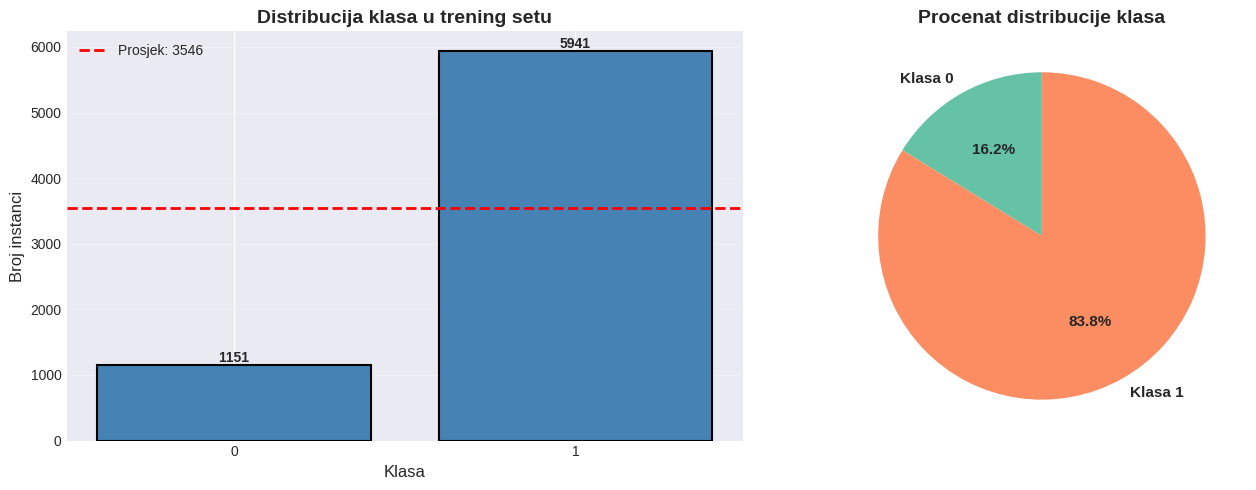


UTICAJ NEBALANSIRANOSTI NA PERFORMANSE

Performanse po klasama:
              precision  recall  f1-score    support
0                0.6096  0.6194    0.6145   247.0000
1                0.9259  0.9230    0.9245  1273.0000
accuracy         0.8737  0.8737    0.8737     0.8737
macro avg        0.7677  0.7712    0.7695  1520.0000
weighted avg     0.8745  0.8737    0.8741  1520.0000

⚠ Problematične klase (nizak recall <0.7):
   - Klasa 0: Recall=0.619, Support=247.0 (manjinska klasa?)


In [16]:
print("=" * 60)
print("ANALIZA NEBALANSIRANOSTI PODATAKA")
print("=" * 60)

# Distribucija klasa u trening setu
train_class_dist = pd.Series(y_train).value_counts().sort_index()
print("\nDistribucija klasa u trening setu:")
print(train_class_dist)
print("\nProcentualna distribucija:")
print((train_class_dist / len(y_train) * 100).round(2))

# Omjer nebalansiranosti
imbalance_ratio = train_class_dist.max() / train_class_dist.min()
print(f"\n⚠ Omjer nebalansiranosti: {imbalance_ratio:.2f}:1")
print(f"   (Najveća klasa / Najmanja klasa)")

# Preporuka za balansiranje
needs_balancing = imbalance_ratio > 1.5
if needs_balancing:
    print("\n⚠ ZAKLJUČAK: Dataset je NEBALANSIRAN!")
    print("   Preporuka: Primjena resampling tehnika (SMOTE, undersampling)")
else:
    print("\n✓ ZAKLJUČAK: Dataset je relativno BALANSIRAN")
    print("   Resampling tehnike nisu neophodne, ali ih možemo testirati")

# Vizualizacija
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
axes[0].bar(train_class_dist.index.astype(str), train_class_dist.values,
            color='steelblue', edgecolor='black', linewidth=1.5)
axes[0].axhline(y=train_class_dist.mean(), color='red', linestyle='--',
                linewidth=2, label=f'Prosjek: {train_class_dist.mean():.0f}')
axes[0].set_xlabel('Klasa', fontsize=12)
axes[0].set_ylabel('Broj instanci', fontsize=12)
axes[0].set_title('Distribucija klasa u trening setu', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)
for i, val in enumerate(train_class_dist.values):
    axes[0].text(i, val, str(val), ha='center', va='bottom', fontweight='bold')

# Pie chart
colors_pie = sns.color_palette("Set2", len(train_class_dist))
axes[1].pie(train_class_dist.values,
            labels=[f'Klasa {i}' for i in train_class_dist.index],
            autopct='%1.1f%%', startangle=90,
            colors=colors_pie,
            textprops={'fontsize': 11, 'fontweight': 'bold'})
axes[1].set_title('Procenat distribucije klasa', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Analiza uticaja nebalansiranosti
print("\n" + "=" * 60)
print("UTICAJ NEBALANSIRANOSTI NA PERFORMANSE")
print("=" * 60)

report_dict = classification_report(y_test, y_test_pred_best, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
print("\nPerformanse po klasama:")
print(report_df[['precision', 'recall', 'f1-score', 'support']].round(4))

# Identifikacija problematičnih klasa
print("\n⚠ Problematične klase (nizak recall <0.7):")
for class_label in train_class_dist.index:
    recall = report_dict[str(class_label)]['recall']
    support = report_dict[str(class_label)]['support']
    if recall < 0.7:
        print(f"   - Klasa {class_label}: Recall={recall:.3f}, Support={support} (manjinska klasa?)")


Ova analiza pokazuje da je dataset značajno nebalansiran, sa omjerom 5.16:1 između najveće (klasa 1) i najmanje klase (klasa 0). Kao posljedica, performanse modela po klasama nisu jednake: dok je klasa 1 precizno i pouzdano predviđena (F1 ≈ 0.9245), manjinska klasa 0 ima znatno niži recall (≈ 0.619), što znači da model propušta veliki broj instanci klase 0. Preporuka je primjena tehnika balansiranja (npr. SMOTE ili undersampling) kako bi se poboljšala detekcija manjinske klase i smanjio problem nebalansiranosti.

# SMOTE (Oversampling)

PRIMJENA SMOTE (Synthetic Minority Over-sampling)

⚙ Primjenjujem SMOTE na trening set...
✓ SMOTE uspješno primijenjen!

POREĐENJE DISTRIBUCIJA
         Originalni dataset  Nakon SMOTE  Razlika
Klasa 0                1151         5941     4790
Klasa 1                5941         5941        0

Ukupno instanci:
  Prije SMOTE:  7092
  Nakon SMOTE:  11882
  Dodato:       4790 (67.5%)


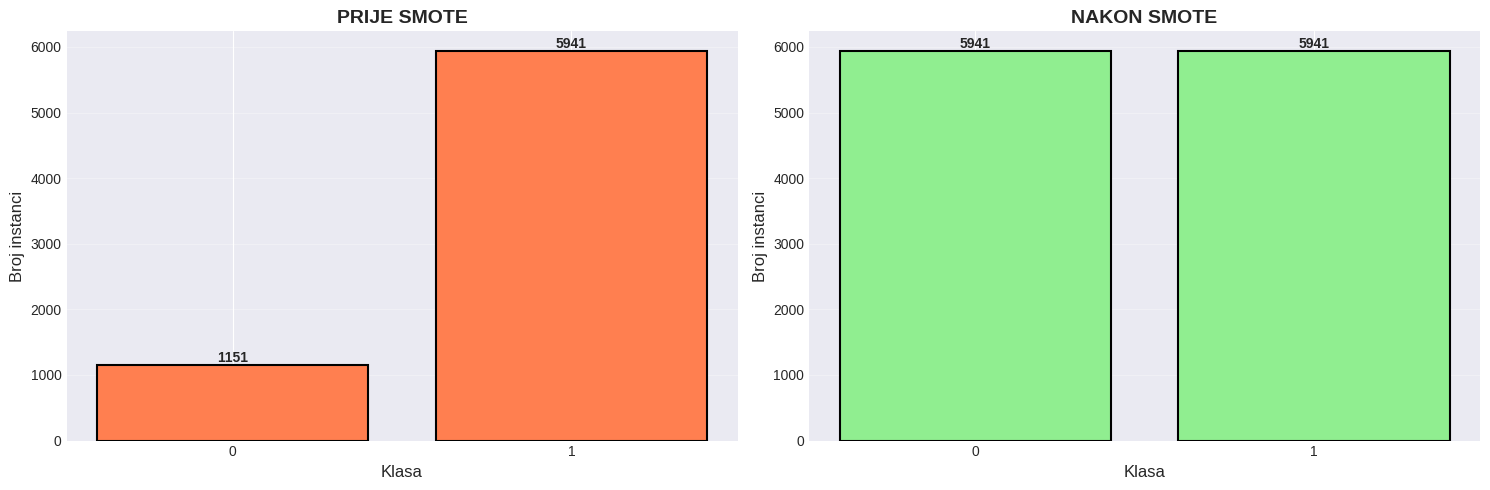

In [17]:
print("=" * 60)
print("PRIMJENA SMOTE (Synthetic Minority Over-sampling)")
print("=" * 60)

# Sačuvaj originalne podatke
X_train_original = X_train_processed.copy()
y_train_original = y_train.copy()

# ⚠ SMOTE radi samo na numeričkim podacima, pa izdvajamo numeričke feature-e iz transformisanog skupa
# Ako si koristio ColumnTransformer sa OneHotEncoder, X_train_processed je sparse matrix
from scipy import sparse

if sparse.issparse(X_train_processed):
    X_train_dense = X_train_processed.toarray()
else:
    X_train_dense = X_train_processed

# Primijeni SMOTE
print("\n⚙ Primjenjujem SMOTE na trening set...")
smote = SMOTE(random_state=42, k_neighbors=5)

try:
    X_train_smote, y_train_smote = smote.fit_resample(X_train_dense, y_train)
    print("✓ SMOTE uspješno primijenjen!")

    # Uporedi distribucije
    original_dist = pd.Series(y_train_original).value_counts().sort_index()
    smote_dist = pd.Series(y_train_smote).value_counts().sort_index()

    print("\n" + "=" * 60)
    print("POREĐENJE DISTRIBUCIJA")
    print("=" * 60)

    comparison_df = pd.DataFrame({
        'Originalni dataset': original_dist.values,
        'Nakon SMOTE': smote_dist.values,
        'Razlika': smote_dist.values - original_dist.values
    }, index=[f'Klasa {i}' for i in original_dist.index])

    print(comparison_df)

    print(f"\nUkupno instanci:")
    print(f"  Prije SMOTE:  {len(y_train_original)}")
    print(f"  Nakon SMOTE:  {len(y_train_smote)}")
    print(f"  Dodato:       {len(y_train_smote) - len(y_train_original)} "
          f"({(len(y_train_smote) - len(y_train_original)) / len(y_train_original) * 100:.1f}%)")

    # Vizualizacija
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Prije SMOTE
    axes[0].bar(original_dist.index.astype(str), original_dist.values,
                color='coral', edgecolor='black', linewidth=1.5)
    axes[0].set_xlabel('Klasa', fontsize=12)
    axes[0].set_ylabel('Broj instanci', fontsize=12)
    axes[0].set_title('PRIJE SMOTE', fontsize=14, fontweight='bold')
    axes[0].grid(axis='y', alpha=0.3)
    for i, (idx, val) in enumerate(original_dist.items()):
        axes[0].text(i, val, str(val), ha='center', va='bottom', fontweight='bold')

    # Nakon SMOTE
    axes[1].bar(smote_dist.index.astype(str), smote_dist.values,
                color='lightgreen', edgecolor='black', linewidth=1.5)
    axes[1].set_xlabel('Klasa', fontsize=12)
    axes[1].set_ylabel('Broj instanci', fontsize=12)
    axes[1].set_title('NAKON SMOTE', fontsize=14, fontweight='bold')
    axes[1].grid(axis='y', alpha=0.3)
    for i, (idx, val) in enumerate(smote_dist.items()):
        axes[1].text(i, val, str(val), ha='center', va='bottom', fontweight='bold')

    plt.tight_layout()
    plt.show()

    smote_success = True

except Exception as e:
    print(f"⚠ Greška pri primjeni SMOTE: {str(e)}")
    print("Nastavljam sa originalnim podacima...")
    X_train_smote = X_train_dense
    y_train_smote = y_train
    smote_success = False

SMOTE (Synthetic Minority Over-sampling Technique) je generisao nove sintetičke primjere za manjinsku klasu (0 – Attrited), tako da je broj instanci u obje klase sada izjednačen na 5941. Ukupan broj trening uzoraka je porastao sa 7092 na 11882, što je povećanje od 67,5%. Ova tehnika omogućava modelu da bolje uči iz manjinske klase i smanjuje pristrasnost prema dominantnoj klasi.

# Evaluacija nakon oversamplinga

EVALUACIJA k-NN MODELA NAKON SMOTE-a (k=8, threshold=0.25)

TAČNOST PO SETOVIMA:
  Trening set:     1.0000 (100.00%)
  Validacioni set: 0.6931 (69.31%)
  Test set:        0.6849 (68.49%)

DETALJNE METRIKE (TEST SET)
✓ Accuracy:  0.6849
✓ Precision: 0.8571
✓ Recall:    0.6849
✓ F1-Score:  0.7261
✓ Kappa:     0.3070

KONFUZIJSKA MATRICA:
[[213  34]
 [445 828]]


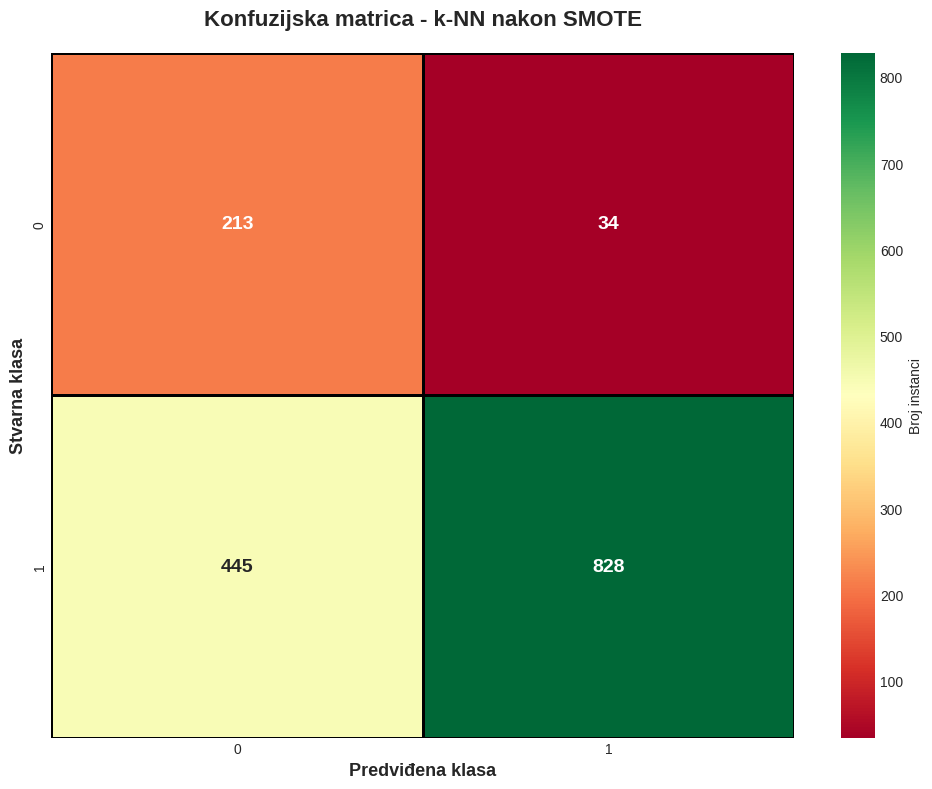


CLASSIFICATION REPORT (TEST SET)
              precision    recall  f1-score   support

           0       0.32      0.86      0.47       247
           1       0.96      0.65      0.78      1273

    accuracy                           0.68      1520
   macro avg       0.64      0.76      0.62      1520
weighted avg       0.86      0.68      0.73      1520


DODATNE METRIKE (BINARNA KLASIFIKACIJA)
✓ Sensitivity (Recall, TPR):  0.6504
✓ Specificity (TNR):          0.8623
✓ PPV (Precision):            0.9606
✓ NPV:                        0.3237
✓ False Positive Rate (FPR):  0.1377
✓ False Negative Rate (FNR):  0.3496


In [18]:
print("=" * 60)
print("EVALUACIJA k-NN MODELA NAKON SMOTE-a (k=8, threshold=0.25)")
print("=" * 60)

# ---- Preprocesor: obavezno osiguraj dense izlaz za KNN ----
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
])

# ---- Pipeline sa SMOTE ----
pipeline_smote = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42, k_neighbors=5)),
    ('knn', KNeighborsClassifier(
        n_neighbors=8,
        weights='distance',
        metric='minkowski',
        p=2
    ))
])

# Fit na originalnom trening setu (X_train, y_train)
pipeline_smote.fit(X_train, y_train)

# ---- Predikcije sa pragom 0.25 za klasu 0 ----
proba_val  = pipeline_smote.predict_proba(X_val)[:, list(pipeline_smote.named_steps['knn'].classes_).index(0)]
proba_test = pipeline_smote.predict_proba(X_test)[:, list(pipeline_smote.named_steps['knn'].classes_).index(0)]

threshold = 0.25
y_val_pred_smote  = np.where(proba_val >= threshold, 0, 1)
y_test_pred_smote = np.where(proba_test >= threshold, 0, 1)

# ---- Accuracy po setovima ----
train_acc_smote = pipeline_smote.score(X_train, y_train)  # score koristi default argmax
val_acc_smote   = accuracy_score(y_val, y_val_pred_smote)
test_acc_smote  = accuracy_score(y_test, y_test_pred_smote)

print("\nTAČNOST PO SETOVIMA:")
print(f"  Trening set:     {train_acc_smote:.4f} ({train_acc_smote*100:.2f}%)")
print(f"  Validacioni set: {val_acc_smote:.4f} ({val_acc_smote*100:.2f}%)")
print(f"  Test set:        {test_acc_smote:.4f} ({test_acc_smote*100:.2f}%)")

# ---- Detaljne metrike za test set ----
accuracy_smote  = accuracy_score(y_test, y_test_pred_smote)
precision_smote = precision_score(y_test, y_test_pred_smote, average='weighted', zero_division=0)
recall_smote    = recall_score(y_test, y_test_pred_smote, average='weighted', zero_division=0)
f1_smote        = f1_score(y_test, y_test_pred_smote, average='weighted', zero_division=0)
kappa_smote     = cohen_kappa_score(y_test, y_test_pred_smote)

print("\n" + "=" * 60)
print("DETALJNE METRIKE (TEST SET)")
print("=" * 60)
print(f"✓ Accuracy:  {accuracy_smote:.4f}")
print(f"✓ Precision: {precision_smote:.4f}")
print(f"✓ Recall:    {recall_smote:.4f}")
print(f"✓ F1-Score:  {f1_smote:.4f}")
print(f"✓ Kappa:     {kappa_smote:.4f}")

# ---- Konfuzijska matrica ----
cm_smote = confusion_matrix(y_test, y_test_pred_smote)
print("\nKONFUZIJSKA MATRICA:")
print(cm_smote)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_smote, annot=True, fmt='d', cmap='RdYlGn',
            cbar_kws={'label': 'Broj instanci'},
            linewidths=2, linecolor='black', annot_kws={'size': 14, 'weight': 'bold'})
plt.title('Konfuzijska matrica - k-NN nakon SMOTE', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Stvarna klasa', fontsize=13, fontweight='bold')
plt.xlabel('Predviđena klasa', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ---- Classification report ----
print("\n" + "=" * 60)
print("CLASSIFICATION REPORT (TEST SET)")
print("=" * 60)
print(classification_report(y_test, y_test_pred_smote))

# ---- Dodatne metrike za binarnu klasifikaciju ----
if len(np.unique(y_train)) == 2:
    tn, fp, fn, tp = cm_smote.ravel()
    specificity_smote = tn / (tn + fp)
    sensitivity_smote = tp / (tp + fn)
    npv_smote = tn / (tn + fn)
    ppv_smote = tp / (tp + fp)

    print("\n" + "=" * 60)
    print("DODATNE METRIKE (BINARNA KLASIFIKACIJA)")
    print("=" * 60)
    print(f"✓ Sensitivity (Recall, TPR):  {sensitivity_smote:.4f}")
    print(f"✓ Specificity (TNR):          {specificity_smote:.4f}")
    print(f"✓ PPV (Precision):            {ppv_smote:.4f}")
    print(f"✓ NPV:                        {npv_smote:.4f}")
    print(f"✓ False Positive Rate (FPR):  {fp/(fp+tn):.4f}")
    print(f"✓ False Negative Rate (FNR):  {fn/(fn+tp):.4f}")


Iako je skup podataka nebalansiran, eksperimentalni rezultati pokazuju da metode oversamplinga (SMOTE, SMOTE-Tomek) narušavaju lokalnu strukturu podataka i značajno pogoršavaju performanse k-NN klasifikatora. Najbolji rezultati ostvareni su bez resamplinga uz prilagođavanje praga odlučivanja.

# Tuning parametara

In [19]:
# ---- Definicija parametara za pretraživanje ----
param_dist = {
    "n_neighbors": list(range(3, 21)),      # broj susjeda
    "weights": ["uniform", "distance"],     # uniform ili distance
    "metric": ["minkowski", "manhattan", "euclidean"],
    "p": [1, 2]                             # samo relevantno za Minkowski
}

# ---- Osnovni KNN model ----
knn_base = KNeighborsClassifier()

# ---- Randomized Search CV ----
search_knn = RandomizedSearchCV(
    estimator=knn_base,
    param_distributions=param_dist,
    n_iter=20,            # koliko kombinacija testirati
    scoring="f1_weighted",# možeš koristiti f1_weighted da balansiraš klase
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# ---- Fit na originalni trening set ----
search_knn.fit(X_train_processed, y_train)

print("Najbolji parametri:")
print(search_knn.best_params_)

print("\nNajbolji CV F1-weighted:")
print(search_knn.best_score_)

# ---- Najbolji model ----
knn_tuned = search_knn.best_estimator_

# ---- Predikcije sa pragom 0.25 za klasu 0 ----
threshold = 0.25
idx0 = list(knn_tuned.classes_).index(0)

y_val_pred_tuned = np.where(knn_tuned.predict_proba(X_val_processed)[:, idx0] >= threshold, 0, 1)
y_test_pred_tuned = np.where(knn_tuned.predict_proba(X_test_processed)[:, idx0] >= threshold, 0, 1)

accuracy_val = accuracy_score(y_val, y_val_pred_tuned)
precision_val = precision_score(y_val, y_val_pred_tuned, average='weighted', zero_division=0)
recall_val = recall_score(y_val, y_val_pred_tuned, average='weighted', zero_division=0)
f1_val = f1_score(y_val, y_val_pred_tuned, average='weighted', zero_division=0)
kappa_val = cohen_kappa_score(y_val, y_val_pred_tuned)

print("\nDETALJNE METRIKE (VALIDATION SET)")
print(f"✓ Accuracy: {accuracy_val:.4f}")
print(f"✓ Precision: {precision_val:.4f}")
print(f"✓ Recall: {recall_val:.4f}")
print(f"✓ F1-score: {f1_val:.4f}")
print(f"✓ Kappa: {kappa_val:.4f}")

# ---- Konfuzijska matrica ----
cm_val = confusion_matrix(y_val, y_val_pred_tuned)
print("\nConfusion matrix (VALIDATION):\n", cm_val)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Najbolji parametri:
{'weights': 'uniform', 'p': 2, 'n_neighbors': 10, 'metric': 'minkowski'}

Najbolji CV F1-weighted:
0.8736040386108227

DETALJNE METRIKE (VALIDATION SET)
✓ Accuracy: 0.8772
✓ Precision: 0.8757
✓ Recall: 0.8772
✓ F1-score: 0.8764
✓ Kappa: 0.5427

Confusion matrix (VALIDATION):
 [[ 149   97]
 [  89 1180]]


Tuning parametara je dao blagu, ali vidljivu poboljšanje, bez potrebe za oversamplingom, što je očekivano jer bazni model već dobro radi na ovom datasetu.